In [3]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from src import Questions
import matplotlib.patches as mpatches

In [25]:
# definitions
models = [
    "gpt_4o",
    "llama31_70B_Inst",
    "Qwen25_72B_Inst",
    "llama31_8B_Inst",
    "Qwen25_7B_Inst",
    "llama32_1B_Inst",
    "Qwen25_1dot5B_Inst"
]
task_types = [
    'mt_and_summarization',
    'syntaxes',
    'knowledge_and_reasoning',
    'semantics',
    'qa_extraction'
]
demography_profiles = [
    "employment_sector",
    "race",
    "education",
    "sex",
    "age",
    "language",
    "nationality_group"
]
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"

In [5]:
# creating a dataframe of all of the annotator profiles
questions = Questions().get_questions()

In [28]:
def calculate_diversity_score(list_of_values):
    if len(list_of_values) < 2:
        return 0  # No diversity if less than 2 elements
    
    total = 0
    count = 0
    for i in range(len(list_of_values)):
        for j in range(i + 1, len(list_of_values)):
            total += abs(list_of_values[i] - list_of_values[j])
            count += 1
    return total / count

model_diversity_scores = []
highlight_data = {
    "gpt_4o" : {},
    "llama31_70B_Inst" : {}
}

for model in models:
    model_specific_scores = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annobj_for_df = {}
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as ao:
            annotator_object = json.load(ao)
        
        annobj_for_df["id"] = annotator_object["id"]
        annobj_for_df.update(**annotator_object["profile"])
        
        for i, (question, scores_for_question) in enumerate(annotator_object["answers"].items()):
            if not scores_for_question["answer"]:
                continue
            else:
                for qdi, scores in scores_for_question["downstream_scores"][model].items():
                    annobj_for_df[qdi] = list(scores.values())[0]
        model_specific_scores.append(annobj_for_df)
    score_df = pd.DataFrame(model_specific_scores)
    exclude_cols = ["id"] + demography_profiles
    task_cols = [col for col in score_df.columns if col not in exclude_cols]
    score_df[task_cols] = (score_df[task_cols] - score_df[task_cols].min()) / (score_df[task_cols].max() - score_df[task_cols].min())
    
    demography_profile_means = {}
    for dp in demography_profiles:
        if model in highlight_data and dp not in highlight_data[model]:
            highlight_data[model][dp] = {}

        demo_avgs = {}
        demo_grouped = score_df.groupby([dp])
        for demo_name, group in demo_grouped:
            # implement here for exceptions
            if dp == "employment_sector":
                group = group[group["language"] == "L1"]
            elif dp == "education":
                group = group[group["language"] == "L1"]
            elif dp == "sex":
                group = group[group["language"] == "L1"]
                
            elif(demo_name == "Black"):
                group = group[group["language"] == "L1"]
            elif(demo_name == "White"):
                group = group[group["language"] == "L1"]
            # implement here for exceptions
            task_scores = []
            for tc in task_cols:
                task_scores.append(group[tc].mean())
            task_average = np.nanmean(task_scores)
            demo_avgs[demo_name[0]] = task_average

            if(model in highlight_data):
                highlight_data[model][dp][demo_name[0]] = task_average
        demography_profile_means[dp] = demo_avgs
    
    diversity_scores = {}
    for dpm_k, dpm_v in demography_profile_means.items():
        diversity_scores[dpm_k] = calculate_diversity_score(list(dpm_v.values()))
    
    model_diversity_scores.append({
        "model" : model,
        **diversity_scores
    })

In [29]:
model_diversity_df = pd.DataFrame(model_diversity_scores)
model_diversity_df

,model,employment_sector,race,education,sex,age,language,nationality_group
0,gpt_4o,0.025521,0.023181,0.026217,0.012963,0.019172,0.036781,0.025735
1,llama31_70B_Inst,0.025910,0.019987,0.017478,0.009591,0.017707,0.025899,0.025332
2,Qwen25_72B_Inst,0.051447,0.015809,0.019639,0.017411,0.023527,0.022264,0.025516
3,llama31_8B_Inst,0.032443,0.008379,0.024536,0.018617,0.017343,0.010427,0.008256
4,Qwen25_7B_Inst,0.009906,0.019841,0.005824,0.012578,0.017525,0.025837,0.024499
5,llama32_1B_Inst,0.053208,0.030927,0.011013,0.002495,0.020318,0.021244,0.014881
6,Qwen25_1dot5B_Inst,0.017428,0.009609,0.013852,0.004621,0.013720,0.012186,0.011235


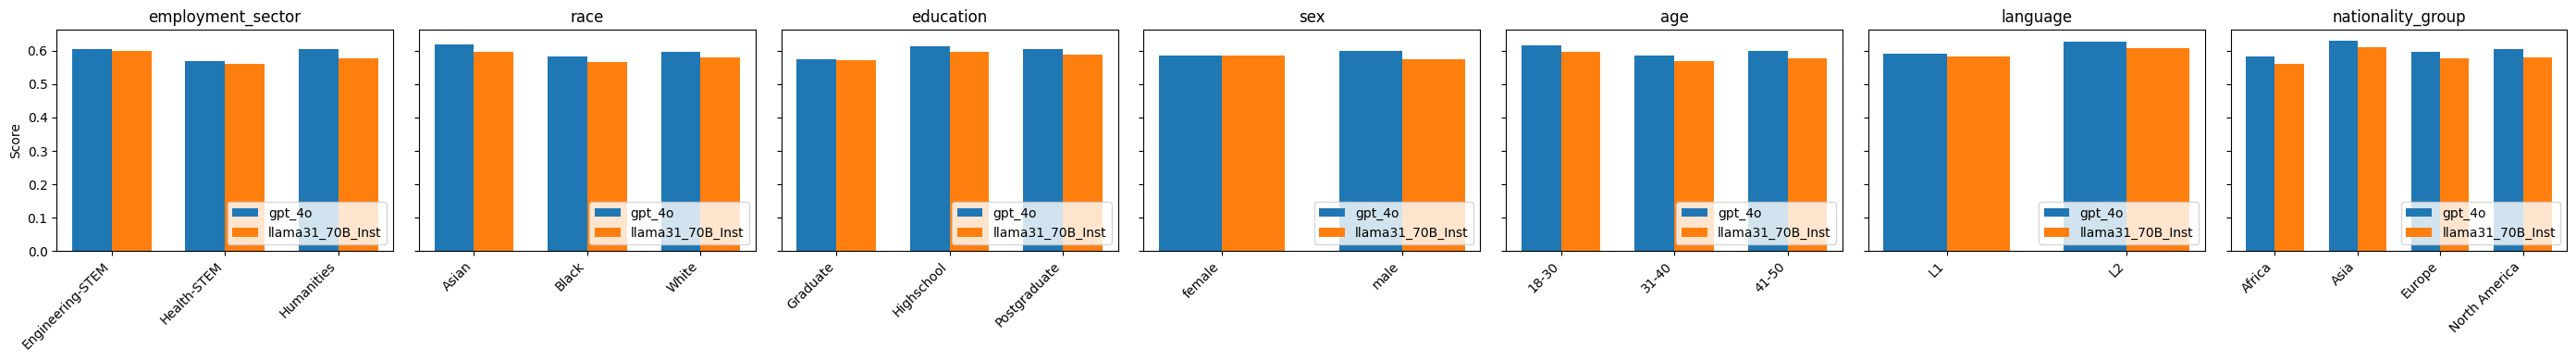

In [30]:
import matplotlib.pyplot as plt

models = list(highlight_data.keys())
categories = list(highlight_data[models[0]].keys())

fig, axes = plt.subplots(1, len(categories), figsize=(4 * len(categories), 4), sharey=True)

for idx, category in enumerate(categories):
    keys = list(highlight_data[models[0]][category].keys())
    gpt_vals = [highlight_data['gpt_4o'][category][k] for k in keys]
    llama_vals = [highlight_data['llama31_70B_Inst'][category][k] for k in keys]
    
    x = range(len(keys))
    width = 0.35

    ax = axes[idx]
    ax.bar([i - width/2 for i in x], gpt_vals, width=width, label='gpt_4o')
    ax.bar([i + width/2 for i in x], llama_vals, width=width, label='llama31_70B_Inst')
    ax.set_xticks(x)
    ax.set_xticklabels(keys, rotation=45, ha='right')
    ax.set_title(category)
    if idx == 0:
        ax.set_ylabel("Score")

    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()